<a href="https://colab.research.google.com/github/PedroNishimura/img-classifier-model/blob/main/imgClassifierModel_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificador de imagens CIFAR-10 com CNN (versão melhorada)

Notebook de estudo: uma **rede neural convolucional (CNN)** em PyTorch que reconhece 10 classes do dataset **CIFAR-10**
(`plane, car, bird, cat, deer, dog, frog, horse, ship, truck`), com imagens minúsculas de 32×32 pixels.

## O que mudou em relação à versão original

| # | Ponto na versão original | O que fazemos aqui |
|---|---|---|
| 1 | A acurácia "de teste" era olhada a cada época; não havia conjunto de **validação** | Separamos 5.000 imagens de validação. O **teste só é usado no final** |
| 2 | Sem *data augmentation* (a rede decorava as imagens de treino) | `RandomCrop` + `RandomHorizontalFlip` **só no treino** |
| 3 | Normalização com `0.5` "chutado" | Média e desvio **calculados** nos dados de treino |
| 4 | Rede minúscula (estilo LeNet, ~62 mil parâmetros) | CNN com 3 blocos, **BatchNorm** e **Dropout** |
| 5 | Taxa de aprendizado fixa | `AdamW` + agendador **OneCycleLR** |
| 6 | Ficava com o modelo da **última** época | Guardamos o **melhor** modelo segundo a validação |
| 7 | Só imprimia números | **Curvas** de treino/validação para diagnosticar overfitting |
| 8 | Acurácia por classe com laço lento | **Matriz de confusão**, relatório por classe e análise de erros |
| 9 | Sem *seed* (resultados mudavam a cada execução) | Sementes fixas para reprodutibilidade |
| 10 | `torch.load` sem `map_location` (quebra ao carregar uma GPU em uma CPU) | Checkpoint completo, carregável em qualquer dispositivo |
| 11 | Inferência com `Resize((32,32))` (achata a imagem) e só a classe top-1 | `Resize` + `CenterCrop`, **top-3**, visualização do que a rede enxerga e alerta de incerteza |
| 12 | Sem ponto de comparação | A rede original é treinada como **baseline** com o mesmo pipeline |

## 0. Conceitos rápidos (para ler antes de rodar)

- **Tensor de imagem:** o PyTorch usa o formato `(N, C, H, W)`: N imagens no lote, C canais (3 = RGB), altura e largura.
- **Convolução (`Conv2d`):** um pequeno filtro (ex.: 3×3) que desliza pela imagem detectando padrões locais (bordas, cantos, texturas). Camadas mais profundas combinam padrões simples em formas mais complexas.
- **ReLU:** `max(0, x)`. Introduz não linearidade; sem ela, empilhar camadas equivaleria a uma só.
- **Pooling (`MaxPool2d`):** reduz a resolução pela metade, guardando o maior valor de cada janela. Torna a rede menos sensível a pequenas translações e reduz o custo.
- **BatchNorm:** normaliza as ativações dentro de cada lote. Deixa o treino mais estável e rápido.
- **Dropout:** desliga neurônios aleatoriamente no treino, para a rede não depender de poucos caminhos (reduz overfitting).
- **Logits → Softmax → probabilidades:** a última camada devolve 10 números sem escala (logits). O *softmax* os transforma em probabilidades que somam 1.
- **CrossEntropyLoss:** a função de erro para classificação. Já inclui o softmax, por isso a última camada **não** tem ativação.
- **Backpropagation + otimizador:** `loss.backward()` calcula o quanto cada peso contribuiu para o erro; `optimizer.step()` ajusta os pesos.
- **Época / lote (batch):** uma época é uma passada completa pelos dados de treino, feita em lotes de `BATCH_SIZE` imagens.
- **Overfitting:** o erro de treino cai, mas o de validação estagna ou piora. A rede está decorando em vez de generalizar.

## 1. Importações e configuração

In [1]:
import copy
import random
import time
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Subset

sns.set_theme(style="whitegrid")

### 1.1 Reprodutibilidade e dispositivo

Fixar as sementes faz duas execuções darem (quase) o mesmo resultado. Em GPU, algumas operações são não determinísticas,
então pequenas diferenças ainda podem aparecer.

In [2]:
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")      # GPU NVIDIA
elif torch.backends.mps.is_available():
    device = torch.device("mps")       # GPU Apple
else:
    device = torch.device("cpu")
print("Dispositivo:", device)

Dispositivo: cuda


### 1.2 Hiperparâmetros

Ficam todos juntos aqui para facilitar experimentos. Em CPU, reduza `EPOCHS` (ex.: 8) para ver o fluxo completo mais rápido.

In [3]:
EPOCHS = 30
BATCH_SIZE = 128
LR_BASELINE = 0.002     # mesmo valor da versão original
LR_V2 = 0.003           # pico do OneCycleLR para a rede nova
WEIGHT_DECAY_V2 = 0.01  # regularização L2 desacoplada do AdamW
VAL_SIZE = 5000         # imagens separadas do treino para validação
NUM_WORKERS = 2         # processos que carregam/augmentam os dados em paralelo

CLASSES = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

## 2. Dados

### 2.1 Download e divisão treino / validação / teste

- **Treino (45.000):** a rede aprende com ele.
- **Validação (5.000):** serve para acompanhar o desempenho, escolher o melhor modelo e comparar ideias.
- **Teste (10.000):** fica guardado para a **avaliação final**. Se você ajustar decisões olhando o teste, ele deixa de ser "dados nunca vistos".

O CIFAR-10 já vem dividido em 50.000 treino + 10.000 teste; nós tiramos a validação de dentro dos 50.000.

In [4]:
raw_train = torchvision.datasets.CIFAR10(root="./dados", train=True, download=True)   # PIL, sem transform

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(raw_train), generator=g).tolist()
val_idx, train_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]
print(f"Treino: {len(train_idx)} | Validação: {len(val_idx)}")

100%|██████████| 170M/170M [27:34<00:00, 103kB/s] 


Treino: 45000 | Validação: 5000


### 2.2 Normalização com estatísticas reais

`Normalize(mean, std)` faz `(pixel - média) / desvio` por canal. Calculamos média e desvio **só no treino**
(usar o teste aqui seria vazamento). O cálculo é feito em blocos para não estourar a memória.

In [5]:
def media_desvio(dados, bloco=5000):
    # dados: array (N, 32, 32, 3) uint8
    soma, soma_q, n = np.zeros(3), np.zeros(3), 0
    for i in range(0, len(dados), bloco):
        lote = dados[i:i + bloco].astype(np.float64) / 255.0
        soma += lote.sum(axis=(0, 1, 2))
        soma_q += (lote ** 2).sum(axis=(0, 1, 2))
        n += lote.shape[0] * lote.shape[1] * lote.shape[2]
    media = soma / n
    desvio = np.sqrt(soma_q / n - media ** 2)
    return tuple(float(round(v, 4)) for v in media), tuple(float(round(v, 4)) for v in desvio)

MEAN, STD = media_desvio(raw_train.data[train_idx])
print("Média por canal (R,G,B):", MEAN)
print("Desvio por canal (R,G,B):", STD)

Média por canal (R,G,B): (0.4913, 0.4822, 0.4466)
Desvio por canal (R,G,B): (0.247, 0.2436, 0.2617)


### 2.3 Transformações: com *augmentation* no treino, sem no resto

*Data augmentation* cria variações plausíveis das imagens a cada época (um cavalo espelhado continua sendo um cavalo).
Isso funciona como "mais dados" e combate o overfitting.

- `RandomCrop(32, padding=4)`: adiciona 4 pixels de borda e recorta 32×32 em posição aleatória (pequenas translações).
- `RandomHorizontalFlip()`: espelha com 50% de chance.

**Validação e teste não recebem augmentation**, porque queremos medir o desempenho nas imagens como elas são.

In [6]:
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Duas "visões" do mesmo conjunto de treino: uma com augmentation, outra sem.
ds_train_full = torchvision.datasets.CIFAR10("./dados", train=True, download=False, transform=train_tf)
ds_eval_full  = torchvision.datasets.CIFAR10("./dados", train=True, download=False, transform=eval_tf)
ds_test       = torchvision.datasets.CIFAR10("./dados", train=False, download=True,  transform=eval_tf)

ds_train = Subset(ds_train_full, train_idx)   # com augmentation
ds_val   = Subset(ds_eval_full,  val_idx)     # sem augmentation
ds_train_noaug = Subset(ds_eval_full, train_idx)  # usado só no experimento opcional da seção 9

pin = device.type == "cuda"
loader_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin)
loader_val = DataLoader(ds_val, batch_size=256, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin)
loader_test = DataLoader(ds_test, batch_size=256, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin)

print("Lotes de treino:", len(loader_train), "| validação:", len(loader_val), "| teste:", len(loader_test))
print("Imagens por classe no treino:", np.bincount(np.array(raw_train.targets)[train_idx]))

Lotes de treino: 352 | validação: 20 | teste: 40
Imagens por classe no treino: [4470 4517 4522 4522 4507 4503 4483 4482 4489 4505]


### 2.4 Olhando os dados

Sempre visualize antes de treinar. As imagens são minúsculas (32×32), então até para uma pessoa
é difícil distinguir gato de cachorro. Isso já indica um teto de desempenho para modelos pequenos.

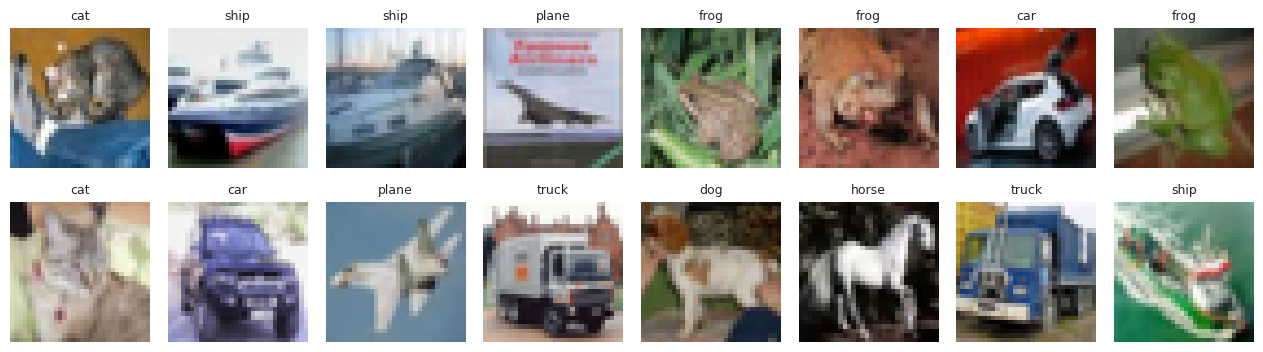

In [7]:
def desnormalizar(t):
    media = torch.tensor(MEAN).view(3, 1, 1)
    desvio = torch.tensor(STD).view(3, 1, 1)
    return (t * desvio + media).clamp(0, 1)

def mostrar_imagens(imgs, titulos, colunas=8):
    linhas = int(np.ceil(len(imgs) / colunas))
    fig, axes = plt.subplots(linhas, colunas, figsize=(1.6 * colunas, 1.9 * linhas))
    for ax in np.array(axes).ravel():
        ax.axis("off")
    for ax, img, titulo in zip(np.array(axes).ravel(), imgs, titulos):
        ax.imshow(desnormalizar(img).permute(1, 2, 0).numpy(), interpolation="nearest")
        ax.set_title(titulo, fontsize=9)
    plt.tight_layout()
    plt.show()

amostra = [ds_test[i] for i in range(16)]
mostrar_imagens([a[0] for a in amostra], [CLASSES[a[1]] for a in amostra])

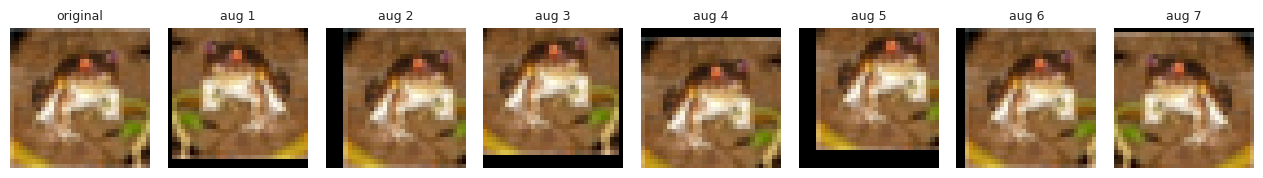

Classe: frog


In [8]:
# O mesmo exemplo passando várias vezes pelo augmentation do treino
pil_img, rotulo = raw_train[0]
variacoes = [eval_tf(pil_img)] + [train_tf(pil_img) for _ in range(7)]
mostrar_imagens(variacoes, ["original"] + [f"aug {i}" for i in range(1, 8)])
print("Classe:", CLASSES[rotulo])

## 3. Arquiteturas

### 3.1 Baseline: a rede da versão original

Estilo LeNet: 2 convoluções 5×5 e 3 camadas lineares. Mantida **sem alterações** para servir de comparação.

### 3.2 Rede nova (`ConvNetV2`)

Três blocos `[Conv → BatchNorm → ReLU] × 2 → MaxPool → Dropout`, dobrando o número de filtros a cada bloco (32 → 64 → 128)
enquanto a resolução cai (32 → 16 → 8 → 4). Depois, um classificador com `Dropout`.

Ideia geral: **a resolução diminui e a quantidade de "características" aumenta**. A rede troca detalhe espacial por significado.

In [9]:
class ConvNetBase(nn.Module):
    # A rede da versão original, sem alterações de arquitetura.
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)       # 32x32 -> 28x28
        self.pool = nn.MaxPool2d(2, 2)        # 28 -> 14
        self.conv2 = nn.Conv2d(6, 16, 5)      # 14 -> 10 -> (pool) 5
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)                    # logits (sem softmax)


def bloco_conv(c_in, c_out, p_dropout):
    # padding=1 com kernel 3x3 mantém a resolução; só o MaxPool a reduz.
    # bias=False porque o BatchNorm já tem o seu próprio deslocamento.
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Dropout(p_dropout),
    )


class ConvNetV2(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(OrderedDict([
            ("bloco1", bloco_conv(3, 32, 0.1)),      # 32x32 -> 16x16
            ("bloco2", bloco_conv(32, 64, 0.2)),     # 16x16 -> 8x8
            ("bloco3", bloco_conv(64, 128, 0.3)),    # 8x8   -> 4x4
        ]))
        self.classifier = nn.Sequential(
            nn.Flatten(),                            # 128 * 4 * 4 = 2048
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, n_classes),               # logits
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

print(f"Parâmetros - baseline: {contar_parametros(ConvNetBase()):,} | V2: {contar_parametros(ConvNetV2()):,}")

Parâmetros - baseline: 62,006 | V2: 814,570


In [10]:
# Como o formato do tensor muda ao atravessar a rede (útil para entender e depurar)
def rastrear_formas(modelo):
    x = torch.zeros(1, 3, 32, 32, device=device)
    modelo.eval()
    print(f"{'entrada':>10} -> {tuple(x.shape)}")
    with torch.no_grad():
        for nome, camada in modelo.features.named_children():
            x = camada(x)
            print(f"{nome:>10} -> {tuple(x.shape)}")
        print(f"{'classifier':>10} -> {tuple(modelo.classifier(x).shape)}")

rastrear_formas(ConvNetV2().to(device))

   entrada -> (1, 3, 32, 32)
    bloco1 -> (1, 32, 16, 16)
    bloco2 -> (1, 64, 8, 8)
    bloco3 -> (1, 128, 4, 4)
classifier -> (1, 10)


## 4. Treinamento

### 4.1 Funções de treino e avaliação

- `run_epoch` serve para treino **e** avaliação. Com `optimizer`, ele atualiza pesos; sem, só mede.
- `model.train()` liga Dropout/BatchNorm em modo de treino; `model.eval()` os põe em modo de inferência. **Esquecer isso é um bug clássico.**
- `torch.set_grad_enabled(False)` na avaliação economiza memória e tempo.
- A acurácia de **treino** é medida com augmentation e Dropout ligados, por isso tende a parecer mais baixa que a de validação no começo. Isso é normal.
- `OneCycleLR` sobe a taxa de aprendizado até um pico e depois a reduz suavemente a quase zero. Em geral converge melhor que uma taxa fixa.
- Guardamos os pesos da **melhor época na validação**, não os da última.

In [11]:
def run_epoch(modelo, loader, criterio, optimizer=None, scheduler=None):
    treinando = optimizer is not None
    modelo.train(treinando)
    perda_total, acertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(treinando):
        for imagens, rotulos in loader:
            imagens = imagens.to(device, non_blocking=True)
            rotulos = rotulos.to(device, non_blocking=True)

            saidas = modelo(imagens)                  # forward
            perda = criterio(saidas, rotulos)

            if treinando:
                optimizer.zero_grad(set_to_none=True)  # zera gradientes antigos
                perda.backward()                       # backpropagation
                optimizer.step()                       # atualiza pesos
                if scheduler is not None:
                    scheduler.step()                   # OneCycleLR avança a cada lote

            perda_total += perda.item() * rotulos.size(0)
            acertos += (saidas.argmax(dim=1) == rotulos).sum().item()
            n += rotulos.size(0)
    return perda_total / n, 100.0 * acertos / n


def fit(modelo, nome, lr, weight_decay=0.0, epochs=EPOCHS, loader_tr=None):
    loader_tr = loader_tr or loader_train
    criterio = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=len(loader_tr))

    historico, melhor_acc, melhor_epoca, melhores_pesos = [], -1.0, 0, None
    print(f"\n=== {nome} ({contar_parametros(modelo):,} parâmetros) ===")
    for epoca in range(1, epochs + 1):
        t0 = time.time()
        loss_tr, acc_tr = run_epoch(modelo, loader_tr, criterio, optimizer, scheduler)
        loss_va, acc_va = run_epoch(modelo, loader_val, criterio)
        historico.append(dict(epoca=epoca, loss_treino=loss_tr, acc_treino=acc_tr,
                              loss_val=loss_va, acc_val=acc_va))
        marca = ""
        if acc_va > melhor_acc:
            melhor_acc, melhor_epoca = acc_va, epoca
            melhores_pesos = copy.deepcopy(modelo.state_dict())
            marca = "  <- melhor"
        print(f"Época {epoca:02d}/{epochs} | treino: loss {loss_tr:.3f}, acc {acc_tr:5.2f}% | "
              f"val: loss {loss_va:.3f}, acc {acc_va:5.2f}% | {time.time() - t0:4.1f}s{marca}")

    modelo.load_state_dict(melhores_pesos)    # volta para a melhor época
    print(f"Melhor validação: {melhor_acc:.2f}% (época {melhor_epoca})")
    return pd.DataFrame(historico)

### 4.2 Treinando o baseline (rede original)

Mesmo pipeline de dados e mesmo número de épocas da rede nova. Assim a comparação é justa entre **as duas redes**.
(Repare que o baseline também ganha augmentation aqui; para medir o efeito da augmentation isoladamente, veja a seção 9.)

In [12]:
set_seed(SEED)
modelo_base = ConvNetBase().to(device)
hist_base = fit(modelo_base, "Baseline (rede original)", lr=LR_BASELINE)


=== Baseline (rede original) (62,006 parâmetros) ===
Época 01/30 | treino: loss 2.114, acc 22.22% | val: loss 1.868, acc 33.70% | 14.9s  <- melhor
Época 02/30 | treino: loss 1.804, acc 34.42% | val: loss 1.668, acc 40.38% | 14.6s  <- melhor
Época 03/30 | treino: loss 1.659, acc 39.22% | val: loss 1.566, acc 43.08% | 14.6s  <- melhor
Época 04/30 | treino: loss 1.574, acc 42.61% | val: loss 1.463, acc 46.70% | 14.5s  <- melhor
Época 05/30 | treino: loss 1.502, acc 45.52% | val: loss 1.387, acc 49.92% | 15.2s  <- melhor
Época 06/30 | treino: loss 1.424, acc 48.54% | val: loss 1.321, acc 52.10% | 15.0s  <- melhor
Época 07/30 | treino: loss 1.367, acc 50.83% | val: loss 1.278, acc 54.18% | 15.2s  <- melhor
Época 08/30 | treino: loss 1.313, acc 53.16% | val: loss 1.203, acc 58.40% | 15.1s  <- melhor
Época 09/30 | treino: loss 1.269, acc 54.55% | val: loss 1.171, acc 57.82% | 14.8s
Época 10/30 | treino: loss 1.227, acc 56.26% | val: loss 1.143, acc 60.10% | 14.8s  <- melhor
Época 11/30 | tre

### 4.3 Treinando a rede nova (`ConvNetV2`)

In [13]:
set_seed(SEED)
modelo_v2 = ConvNetV2().to(device)
hist_v2 = fit(modelo_v2, "ConvNetV2", lr=LR_V2, weight_decay=WEIGHT_DECAY_V2)


=== ConvNetV2 (814,570 parâmetros) ===
Época 01/30 | treino: loss 1.795, acc 32.93% | val: loss 1.502, acc 46.32% | 17.0s  <- melhor
Época 02/30 | treino: loss 1.412, acc 48.29% | val: loss 1.120, acc 59.92% | 16.6s  <- melhor
Época 03/30 | treino: loss 1.202, acc 57.01% | val: loss 1.083, acc 62.36% | 16.7s  <- melhor
Época 04/30 | treino: loss 1.070, acc 62.16% | val: loss 0.982, acc 65.58% | 16.5s  <- melhor
Época 05/30 | treino: loss 0.984, acc 65.31% | val: loss 1.071, acc 64.22% | 16.4s
Época 06/30 | treino: loss 0.919, acc 68.12% | val: loss 0.817, acc 71.38% | 16.5s  <- melhor
Época 07/30 | treino: loss 0.858, acc 70.52% | val: loss 0.759, acc 74.38% | 16.4s  <- melhor
Época 08/30 | treino: loss 0.798, acc 72.94% | val: loss 0.814, acc 72.52% | 16.4s
Época 09/30 | treino: loss 0.740, acc 74.68% | val: loss 0.661, acc 77.30% | 16.5s  <- melhor
Época 10/30 | treino: loss 0.694, acc 76.74% | val: loss 0.611, acc 79.46% | 16.4s  <- melhor
Época 11/30 | treino: loss 0.662, acc 77.5

## 5. Diagnóstico: curvas de aprendizado

Como ler:
- **Treino e validação caem juntos** → o modelo ainda está aprendendo.
- **Treino cai, validação estagna ou sobe** → **overfitting** (foi exatamente o que a versão original mostrava: a perda de treino descendo de 1,58 para 0,76 enquanto a acurácia de teste ficava parada em ~64%).
- **Os dois ruins e parecidos** → **underfitting**: o modelo é pequeno demais ou o treino é curto.
- **Distância entre as curvas** = lacuna de generalização.

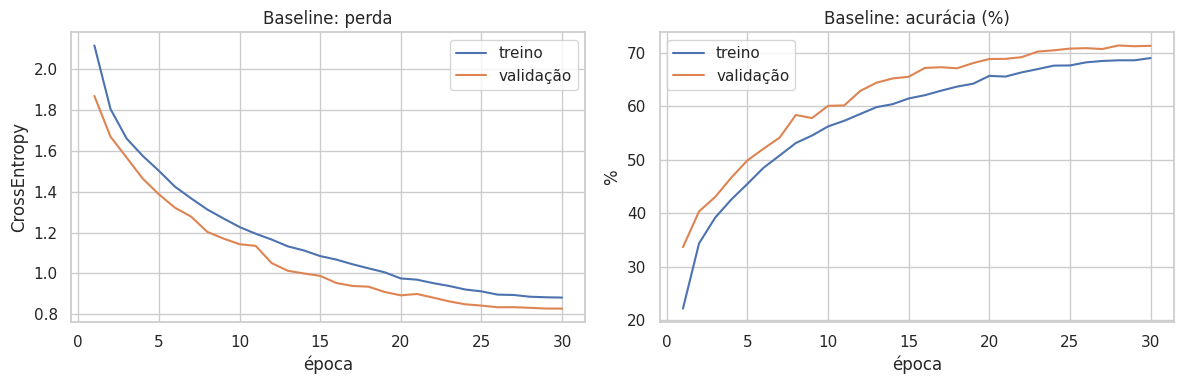

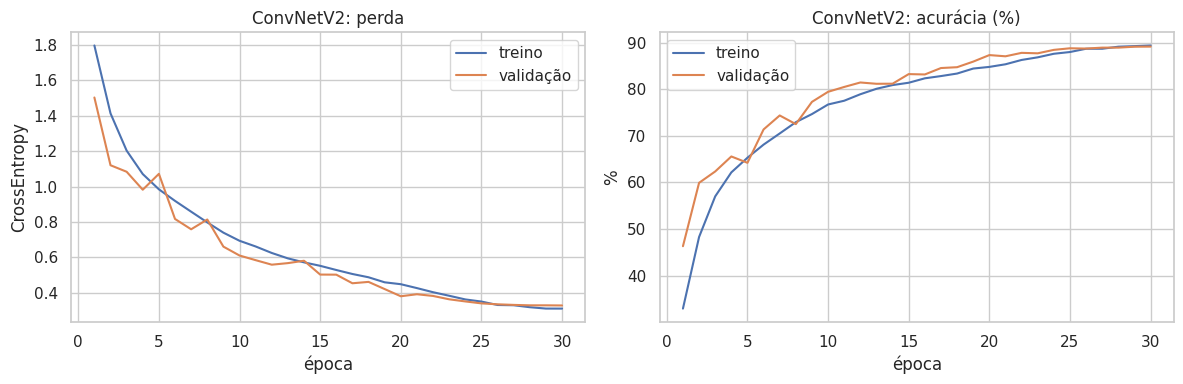

In [14]:
def plotar_historico(hist, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist.epoca, hist.loss_treino, label="treino")
    axes[0].plot(hist.epoca, hist.loss_val, label="validação")
    axes[0].set(title=f"{titulo}: perda", xlabel="época", ylabel="CrossEntropy")
    axes[0].legend()
    axes[1].plot(hist.epoca, hist.acc_treino, label="treino")
    axes[1].plot(hist.epoca, hist.acc_val, label="validação")
    axes[1].set(title=f"{titulo}: acurácia (%)", xlabel="época", ylabel="%")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plotar_historico(hist_base, "Baseline")
plotar_historico(hist_v2, "ConvNetV2")

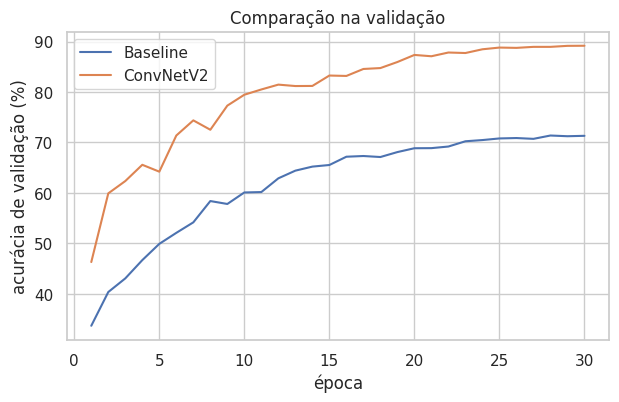

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(hist_base.epoca, hist_base.acc_val, label="Baseline")
plt.plot(hist_v2.epoca, hist_v2.acc_val, label="ConvNetV2")
plt.xlabel("época")
plt.ylabel("acurácia de validação (%)")
plt.title("Comparação na validação")
plt.legend()
plt.show()

## 6. Avaliação final no conjunto de teste

Só agora usamos o teste, **uma única vez por modelo**. A decisão de qual rede é a "oficial" (a V2) foi tomada
antes, com base na arquitetura e na validação, e não olhando o teste.

`avaliar` devolve as previsões, os rótulos reais e as probabilidades. A partir da **matriz de confusão** dá para tirar a acurácia por classe sem laços lentos
(a diagonal tem os acertos; a soma da linha, o total de cada classe).

In [16]:
def avaliar(modelo, loader):
    modelo.eval()
    todas_prev, todos_rot, todas_prob = [], [], []
    with torch.no_grad():
        for imagens, rotulos in loader:
            probs = F.softmax(modelo(imagens.to(device)), dim=1).cpu()
            todas_prob.append(probs)
            todas_prev.append(probs.argmax(dim=1))
            todos_rot.append(rotulos)
    return (torch.cat(todas_prev).numpy(), torch.cat(todos_rot).numpy(), torch.cat(todas_prob).numpy())

prev_base, y_test, prob_base = avaliar(modelo_base, loader_test)
prev_v2, _, prob_v2 = avaliar(modelo_v2, loader_test)

acc_base = 100 * (prev_base == y_test).mean()
acc_v2 = 100 * (prev_v2 == y_test).mean()
print(f"Acurácia no teste | Baseline: {acc_base:.2f}% | ConvNetV2: {acc_v2:.2f}%")
print("Acurácia de referência da versão original (12 épocas, sem validação): 64.45%")

Acurácia no teste | Baseline: 69.80% | ConvNetV2: 88.55%
Acurácia de referência da versão original (12 épocas, sem validação): 64.45%


In [17]:
cm_base = confusion_matrix(y_test, prev_base)
cm_v2 = confusion_matrix(y_test, prev_v2)

por_classe = pd.DataFrame({
    "baseline": 100 * cm_base.diagonal() / cm_base.sum(axis=1),
    "ConvNetV2": 100 * cm_v2.diagonal() / cm_v2.sum(axis=1),
}, index=CLASSES).round(1)
por_classe["ganho (pp)"] = (por_classe["ConvNetV2"] - por_classe["baseline"]).round(1)
por_classe

,baseline,ConvNetV2,ganho (pp)
plane,75.8,88.6,12.8
car,82.1,95.8,13.7
bird,54.5,83.3,28.8
cat,46.4,74.1,27.7
deer,63.0,88.1,25.1
dog,62.8,83.2,20.4
frog,83.4,93.7,10.3
horse,70.9,91.3,20.4
ship,80.6,94.4,13.8
truck,78.5,93.0,14.5


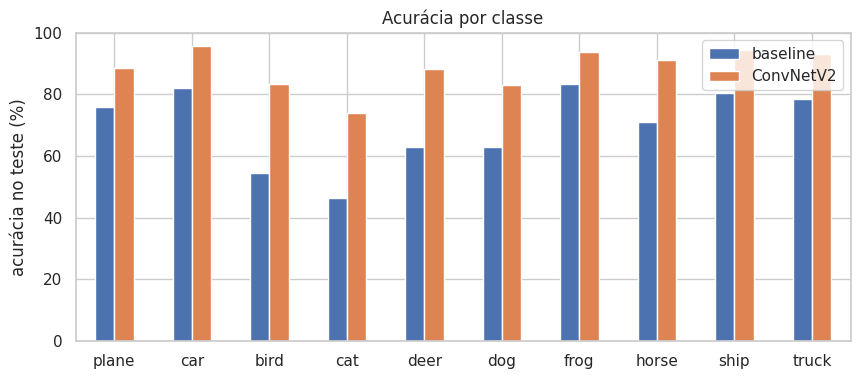

In [18]:
por_classe[["baseline", "ConvNetV2"]].plot.bar(figsize=(10, 4), rot=0)
plt.ylabel("acurácia no teste (%)")
plt.title("Acurácia por classe")
plt.ylim(0, 100)
plt.show()

In [19]:
print(classification_report(y_test, prev_v2, target_names=CLASSES, digits=3))

              precision    recall  f1-score   support

       plane      0.896     0.886     0.891      1000
         car      0.934     0.958     0.946      1000
        bird      0.864     0.833     0.848      1000
         cat      0.788     0.741     0.764      1000
        deer      0.865     0.881     0.873      1000
         dog      0.824     0.832     0.828      1000
        frog      0.888     0.937     0.912      1000
       horse      0.919     0.913     0.916      1000
        ship      0.937     0.944     0.940      1000
       truck      0.934     0.930     0.932      1000

    accuracy                          0.885     10000
   macro avg      0.885     0.886     0.885     10000
weighted avg      0.885     0.885     0.885     10000



### 6.1 Matriz de confusão

Cada linha é a classe **real**; cada coluna, a **prevista**. Normalizamos por linha: o valor mostra "dos exemplos desta classe, que fração foi para cada previsão".
Fora da diagonal estão os erros; procure **pares de classes parecidas** (gato↔cachorro, carro↔caminhão).

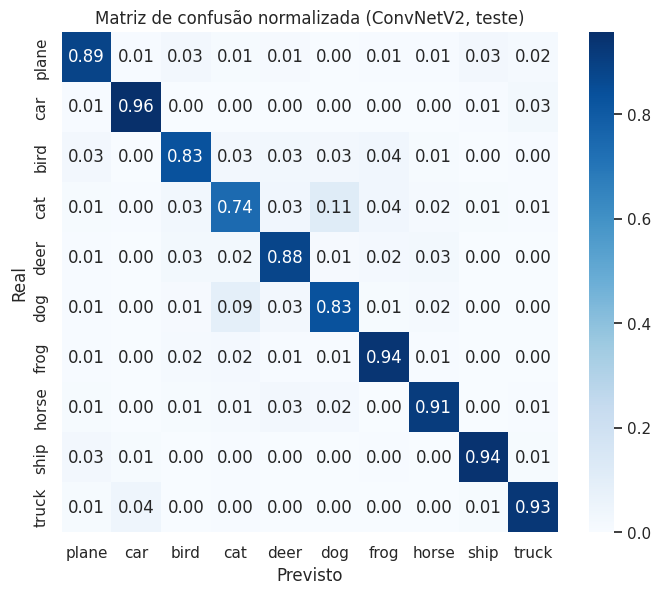

,real,previsto,erros
0,cat,dog,113
1,dog,cat,91
2,truck,car,44
3,bird,frog,36
4,cat,frog,36
5,cat,deer,34
6,bird,deer,33
7,cat,bird,32


In [20]:
cm_norm = cm_v2 / cm_v2.sum(axis=1, keepdims=True)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de confusão normalizada (ConvNetV2, teste)")
plt.show()

# Os pares mais confundidos
fora = [(CLASSES[i], CLASSES[j], int(cm_v2[i, j]))
        for i in range(10) for j in range(10) if i != j]
pd.DataFrame(sorted(fora, key=lambda t: -t[2])[:8], columns=["real", "previsto", "erros"])

## 7. A rede sabe quando está errada?

O softmax devolve "confiança", mas **confiança alta não garante acerto**: redes neurais costumam ser superconfiantes.
Compare a distribuição da confiança nos acertos e nos erros. Se os erros também têm confiança alta, não use um limiar de confiança como única barreira de segurança.

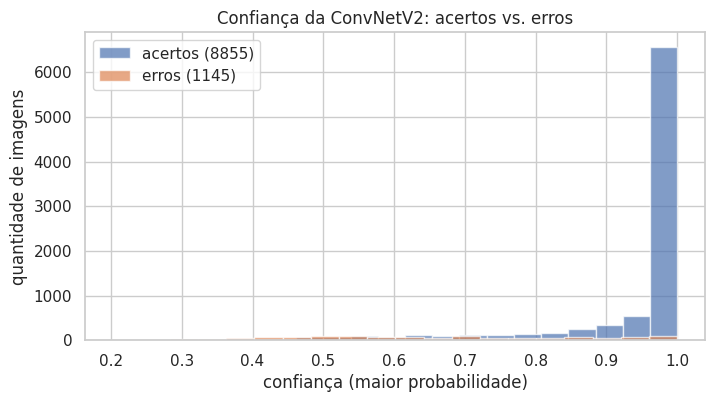

Confiança média nos acertos: 0.94 | nos erros: 0.66


In [21]:
conf = prob_v2.max(axis=1)
acertou = prev_v2 == y_test

plt.figure(figsize=(8, 4))
plt.hist(conf[acertou], bins=20, alpha=0.7, label=f"acertos ({acertou.sum()})")
plt.hist(conf[~acertou], bins=20, alpha=0.7, label=f"erros ({(~acertou).sum()})")
plt.xlabel("confiança (maior probabilidade)")
plt.ylabel("quantidade de imagens")
plt.title("Confiança da ConvNetV2: acertos vs. erros")
plt.legend()
plt.show()

if (~acertou).any():
    print(f"Confiança média nos acertos: {conf[acertou].mean():.2f} | nos erros: {conf[~acertou].mean():.2f}")
else:
    print("Nenhum erro encontrado.")

## 8. Análise de erros: olhando as imagens

Métricas dizem **quanto** erra; as imagens dizem **por quê**. Abaixo estão os erros em que a rede estava **mais confiante**.
Pergunte-se: o rótulo está certo? A imagem é ambígua? O objeto está cortado ou muito pequeno?

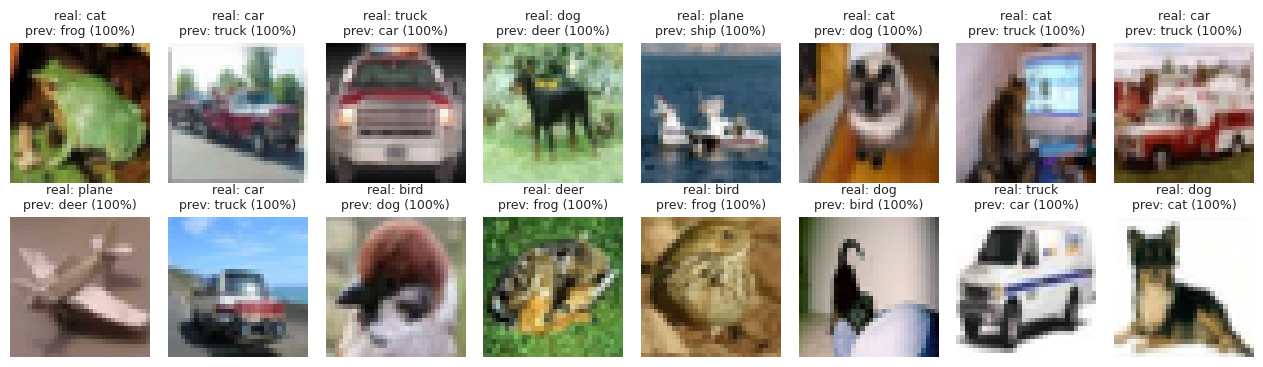

In [22]:
idx_erros = np.where(~acertou)[0]
mais_confiantes = idx_erros[np.argsort(-conf[idx_erros])][:16]

if len(mais_confiantes) == 0:
    print("Nenhum erro para mostrar.")
else:
    imgs = [ds_test[i][0] for i in mais_confiantes]
    titulos = [f"real: {CLASSES[y_test[i]]}\nprev: {CLASSES[prev_v2[i]]} ({conf[i]:.0%})" for i in mais_confiantes]
    mostrar_imagens(imgs, titulos)

## 9. (Opcional) Experimento: quanto a *augmentation* ajuda?

Em vez de supor, **meça**. Treinamos a mesma `ConvNetV2` sem augmentation e comparamos a validação.
Fica desligado por padrão porque dobra o tempo de treino; mude para `True` para rodar.

In [23]:
RODAR_ABLACAO = False

if RODAR_ABLACAO:
    loader_noaug = DataLoader(ds_train_noaug, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=pin)
    set_seed(SEED)
    modelo_noaug = ConvNetV2().to(device)
    hist_noaug = fit(modelo_noaug, "ConvNetV2 sem augmentation", lr=LR_V2,
                     weight_decay=WEIGHT_DECAY_V2, loader_tr=loader_noaug)
    plt.figure(figsize=(7, 4))
    plt.plot(hist_v2.epoca, hist_v2.acc_val, label="com augmentation")
    plt.plot(hist_noaug.epoca, hist_noaug.acc_val, label="sem augmentation")
    plt.xlabel("época"); plt.ylabel("acurácia de validação (%)"); plt.legend()
    plt.show()

## 10. Salvando e carregando o modelo

Salvamos um **checkpoint** com os pesos (`state_dict`) **e** tudo que a inferência precisa repetir (classes, média e desvio).
`map_location=device` permite carregar um modelo treinado em GPU numa máquina só com CPU, e `weights_only=True` é a forma segura de carregar (não executa código arbitrário).

In [24]:
CAMINHO = "model_img_v2.pth"
torch.save({
    "state_dict": modelo_v2.state_dict(),
    "classes": CLASSES,
    "mean": MEAN,
    "std": STD,
    "arquitetura": "ConvNetV2",
}, CAMINHO)
print("Modelo salvo em:", CAMINHO)

ckpt = torch.load(CAMINHO, map_location=device, weights_only=True)
model_load = ConvNetV2().to(device)
model_load.load_state_dict(ckpt["state_dict"])
model_load.eval()
print("Checkpoint carregado.")

Modelo salvo em: model_img_v2.pth
Checkpoint carregado.


## 11. Classificando as suas próprias imagens

Mudanças na inferência:
- `Resize(32)` + `CenterCrop(32)`: reduz mantendo a proporção e recorta o centro, em vez de **achatar** a imagem como `Resize((32, 32))`.
- A normalização usa a média e o desvio **do treino**, guardados no checkpoint.
- Mostramos **o que a rede realmente enxerga** (32×32) e as **3 classes mais prováveis**.

**Limitações importantes:**
1. A rede só conhece **10 classes**. Mostre uma pessoa ou uma bicicleta e ela vai responder com a classe "menos errada", muitas vezes com alta confiança.
2. Fotos de celular têm milhões de pixels; reduzidas a 32×32, ficam bem diferentes do CIFAR-10. Objetos grandes, centralizados e com fundo simples funcionam melhor.

In [25]:
inference_tf = transforms.Compose([
    transforms.Resize(32),
    transforms.CenterCrop(32),
    transforms.ToTensor(),
    transforms.Normalize(ckpt["mean"], ckpt["std"]),
])

def classificar_imagem(caminho, modelo, top_k=3, limiar=0.60):
    try:
        img = Image.open(caminho).convert("RGB")
    except Exception as e:
        print(f"Não foi possível abrir '{caminho}': {e}")
        return None

    x = inference_tf(img).unsqueeze(0).to(device)       # [1, 3, 32, 32]: o modelo espera um lote
    modelo.eval()
    with torch.no_grad():
        probs = F.softmax(modelo(x), dim=1)[0].cpu()

    top_p, top_i = probs.topk(top_k)
    visto = desnormalizar(x[0].cpu()).permute(1, 2, 0).numpy()

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2, 1, 2]})
    axes[0].imshow(img)
    axes[0].set_title("Original")
    axes[0].axis("off")
    axes[1].imshow(visto, interpolation="nearest")
    axes[1].set_title("O que a rede vê (32x32)")
    axes[1].axis("off")
    axes[2].barh([CLASSES[i] for i in top_i][::-1], (top_p * 100).tolist()[::-1])
    axes[2].set_xlim(0, 100)
    axes[2].set_xlabel("probabilidade (%)")
    aviso = "  [incerto]" if top_p[0] < limiar else ""
    fig.suptitle(f"Previsão: {CLASSES[top_i[0]]} ({top_p[0] * 100:.1f}%){aviso}")
    plt.tight_layout()
    plt.show()
    return [(CLASSES[i], float(p)) for p, i in zip(top_p, top_i)]

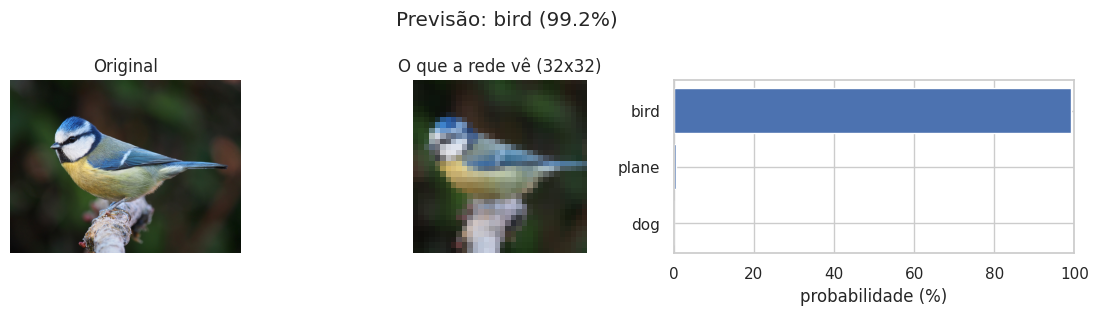

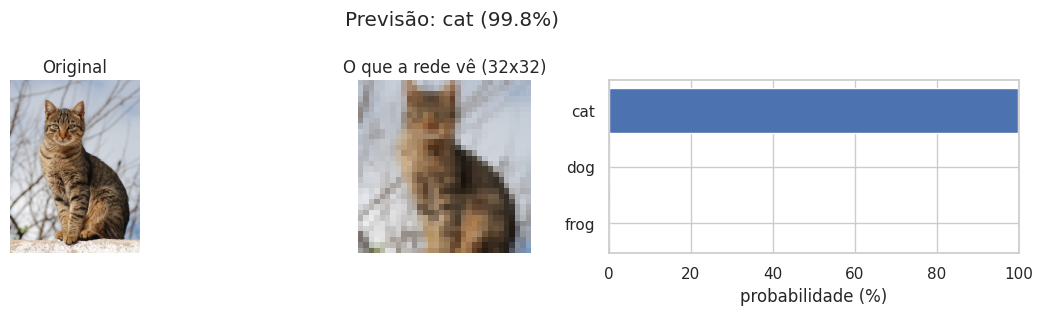

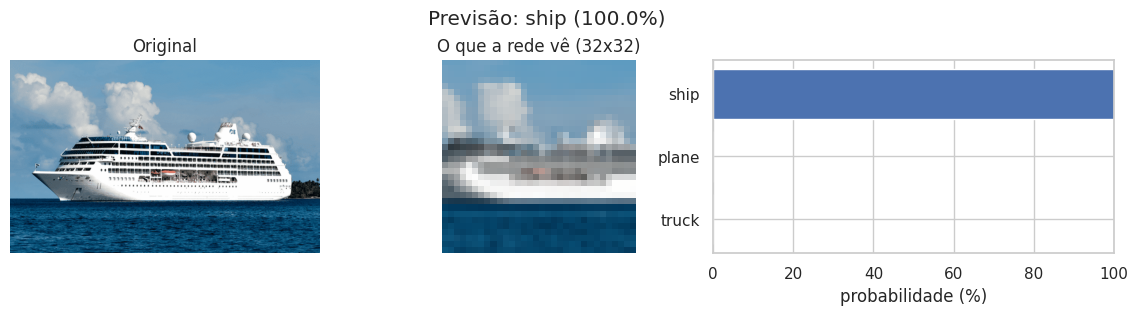

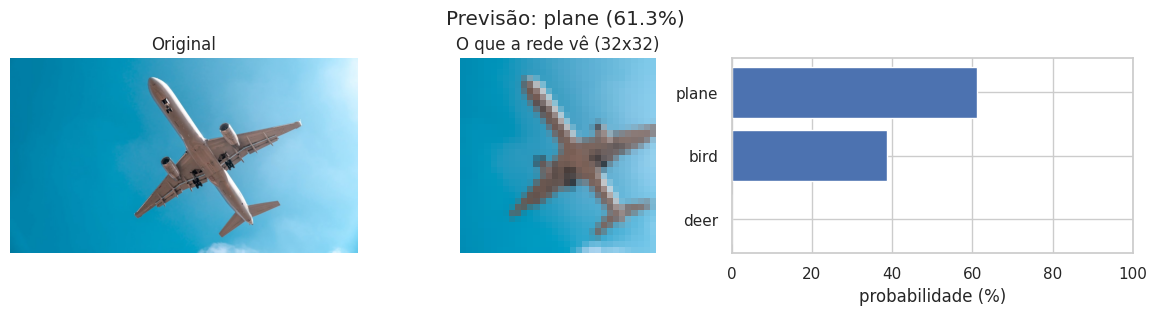

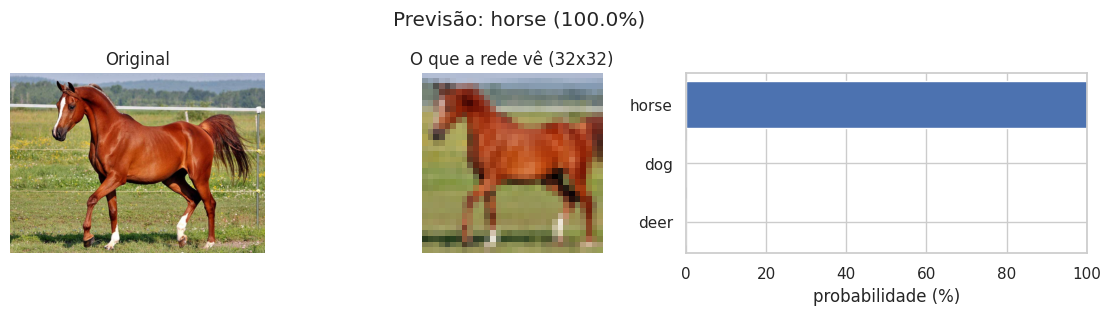

In [26]:
# Ajuste os nomes. No Colab, envie os arquivos pelo painel lateral de arquivos.
IMAGENS = ["imagem1.jpg", "imagem2.jpg", "imagem3.png", "imagem4.jpg", "imagem5.jpg"]

for caminho in IMAGENS:
    classificar_imagem(caminho, model_load)

## 12. Conclusões e lições

1. **Validação separada do teste.** Decisões (épocas, taxa de aprendizado, arquitetura) se tomam na validação; o teste fica para o veredito final.
2. **Leia as curvas, não só o número final.** Elas dizem se o problema é overfitting, underfitting ou falta de treino.
3. **Augmentation, BatchNorm e Dropout** são ferramentas de generalização baratas e muito eficazes em visão computacional.
4. **Meça mudanças isoladamente** (como na seção 9). Melhorar várias coisas de uma vez impede saber o que ajudou.
5. **Acurácia global esconde classes difíceis.** Olhe a matriz de confusão: gato, cachorro e pássaro costumam ser os piores.
6. **Confiança não é correção.** Redes erram com alta confiança, e fora do domínio (outras classes, fotos reais) isso é pior.
7. **Pré-processamento idêntico no treino/inferência.** Qualquer diferença (tamanho, normalização, ordem dos canais) degrada o resultado silenciosamente.

### Próximos passos sugeridos
- **Transfer learning** (ex.: ResNet18 pré-treinada no ImageNet, ajustada ao CIFAR-10): costuma passar de 90% com poucos minutos de treino.
- Augmentations mais fortes (`AutoAugment`, `Cutout`, `MixUp`) e `label_smoothing` na loss.
- *Test-time augmentation* (média das previsões da imagem e do seu espelho).
- Treinar com precisão mista (`torch.autocast`) para acelerar em GPU.
- Exportar para ONNX para usar o modelo fora do Python.